In [18]:
import fibril_tracing as ft
import numpy as np 
import scipy.ndimage
import matplotlib.pyplot as plt
from astropy.io import fits, ascii
from astropy.visualization import ImageNormalize, AsinhStretch
import h5py
import dask.array as da
from astropy.time import Time
import astropy.units as u
from tqdm.notebook import tqdm
from destretch import destretchSeq
from sun_blinker import ImageBlinker
from skimage.measure import block_reduce
from scipy.ndimage import maximum_filter
from skimage.registration import phase_cross_correlation

In [2]:
file_Hbeta_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/Hbeta_BJOLO_pr.hdf5")
Hbeta_pr_set = file_Hbeta_pr["vbi_img"]
Hbeta_pr_da = da.from_array(Hbeta_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Hbeta_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/Hbeta_BJOLO_date_avg.txt")["DATE-AVG"])

In [3]:
file_Gband_pr = h5py.File("../../data/pid_1_123_aux/plot_ready/Gband_AEZDV_pr.hdf5")
Gband_pr_set = file_Gband_pr["vbi_img"]
Gband_pr_da = da.from_array(Gband_pr_set, chunks=(1, 4096 - 128*2, 4096 - 128*2))
Gband_date_obs = Time(ascii.read("../../data/pid_1_123_aux/plot_ready/Gband_AEZDV_date_avg.txt")["DATE-AVG"])

In [4]:
sotsp_start = Time('2022-10-24T19:10:04.393')
sotsp_end = Time('2022-10-24T19:18:40.215')

In [5]:
np.where((Hbeta_date_obs > sotsp_start) & (Hbeta_date_obs < sotsp_end))

(array([ 72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,  84,
         85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,
         98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110,
        111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123,
        124, 125, 126, 127]),)

In [6]:
np.where((Gband_date_obs > sotsp_start) & (Gband_date_obs < sotsp_end))

(array([ 72,  73,  74,  75,  76,  77,  78,  79,  80,  81,  82,  83,  84,
         85,  86,  87,  88,  89,  90,  91,  92,  93,  94,  95,  96,  97,
         98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110,
        111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123,
        124, 125, 126, 127]),)

In [7]:
(sotsp_end - sotsp_start).to(u.min)

<Quantity 8.59703333 min>

In [8]:
select_indices = np.arange(72, 128, 5)

In [9]:
select_indices

array([ 72,  77,  82,  87,  92,  97, 102, 107, 112, 117, 122, 127])

In [44]:
def make_single_destretch(Hbeta_image, Gband_image,
        xslice=slice(128,512+128), yslice=slice(128,512+128)):
    shifts, _, _ = phase_cross_correlation(Hbeta_image[yslice, xslice],
                        Gband_image[yslice, xslice], upsample_factor=10)
    Gband_image = scipy.ndimage.shift(Gband_image, shifts)[128:-128,128:-128]
    Hbeta_image = Hbeta_image[128:-128,128:-128]
    
    Hbeta_image_destretched, Gband_image_destretched = destretchSeq(
        np.array([Hbeta_image, Gband_image]),
        [128,96],
        rMean=3,
        globalTrack=[1500,1500,256]
    )

    return Hbeta_image_destretched, Gband_image_destretched

In [53]:
load_destretch = False

if load_destretch:
    Hbeta_image_destretched = np.load("../../sav/fibril_tracing/Hbeta_image_destretched.npy")
    Gband_image_destretched = np.load("../../sav/fibril_tracing/Gband_image_destretched.npy")
else:
    Hbeta_image_destretched = np.zeros((len(select_indices),4096 - 128*4,4096 - 128*4))
    Gband_image_destretched = np.zeros((len(select_indices),4096 - 128*4,4096 - 128*4))
    for ii, select_index_ in enumerate(select_indices):
        Hbeta_image_ = Hbeta_pr_da[select_index_].compute()
        Gband_image_ = Gband_pr_da[select_index_].compute()
        Hbeta_image_destretched_, Gband_image_destretched_ = make_single_destretch(
            Hbeta_image_,
            Gband_image_,
            xslice=slice(128,3840-128), yslice=slice(128,3840-128)
        )
        
        Hbeta_image_destretched[ii] = Hbeta_image_destretched_
        Gband_image_destretched[ii] = Gband_image_destretched_
    
    np.save("../../sav/fibril_tracing/Hbeta_image_destretched.npy", Hbeta_image_destretched)
    np.save("../../sav/fibril_tracing/Gband_image_destretched.npy", Gband_image_destretched)


In [52]:
ImageBlinker(*make_single_destretch(
    Hbeta_pr_da[select_indices[10]].compute(),
    Gband_pr_da[select_indices[10]].compute(),
    xslice=slice(128,3840-128), yslice=slice(128,3840-128)
    ),
    )

In [54]:
for ii in range(12):
    ImageBlinker(Hbeta_image_destretched[ii], Gband_image_destretched[ii])

In [55]:
def get_fibril_mask(Hbeta_image, Gband_image):
    P_v3 = ft.Params()   
    res_v3 = ft.run_pipeline(Hbeta_image, Gband_image, bin=1, centerline="nms", P=P_v3, verbose=False)

    return res_v3

In [56]:
fibril_results = []
for ii in tqdm(range(len(select_indices))):
    fibril_results.append(get_fibril_mask(Hbeta_image_destretched[ii], Gband_image_destretched[ii]))

  0%|          | 0/12 [00:00<?, ?it/s]

In [57]:
list(fibril_results[0].keys())

['bin',
 'centerline',
 'params',
 'poly_coef',
 'noise',
 'dark_gate_frac',
 'bp_zone_frac',
 'low',
 'high',
 'trim_info',
 'timings',
 'total_time',
 'n_links',
 'n_kinks_split',
 'branch_table',
 'trace_table',
 'polylines',
 'field_theta',
 'field_coh',
 'merged',
 'resp',
 'sigma_best',
 'nr',
 'nc',
 'mask',
 'bp_zone',
 'skeleton_raw',
 'skeleton',
 'straight_skeleton',
 'linked_skeleton',
 'traces',
 'grouped_mask',
 'Hb',
 'Gb']

In [58]:
def prepare_skeleton(mask, block=4, thickness=2):
    small = block_reduce(
        mask.astype(np.uint8),
        block_size=(block, block),
        func=np.max
    )

    if thickness > 1:
        small = maximum_filter(small, size=thickness)
    
    return small

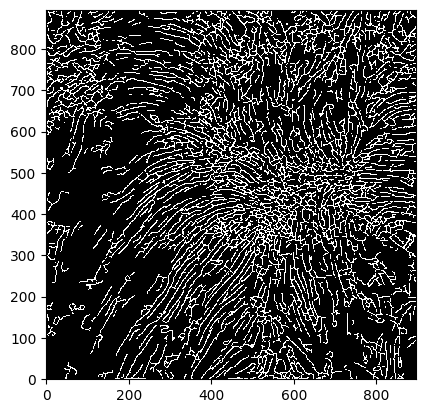

In [59]:
plt.imshow(prepare_skeleton(fibril_results[0]["skeleton_raw"]), origin="lower",
    cmap="gray", vmin=0, vmax=1, interpolation="nearest")

In [60]:
fibril_mask_small_display = []
fibril_mask = []
fibril_merge = []
fibril_skel_raw = []

for fibril_result_ in fibril_results:
    fibril_mask.append(fibril_result_["traces"])
    fibril_mask_small_display.append(prepare_skeleton(fibril_result_["traces"]))
    fibril_merge.append(fibril_result_["merged"])
    fibril_skel_raw.append(fibril_result_["skeleton_raw"])
fibril_mask = np.asarray(fibril_mask)
fibril_mask_small_display = np.asarray(fibril_mask_small_display)
fibril_merge = np.asarray(fibril_merge)
fibril_skel_raw = np.asarray(fibril_skel_raw)


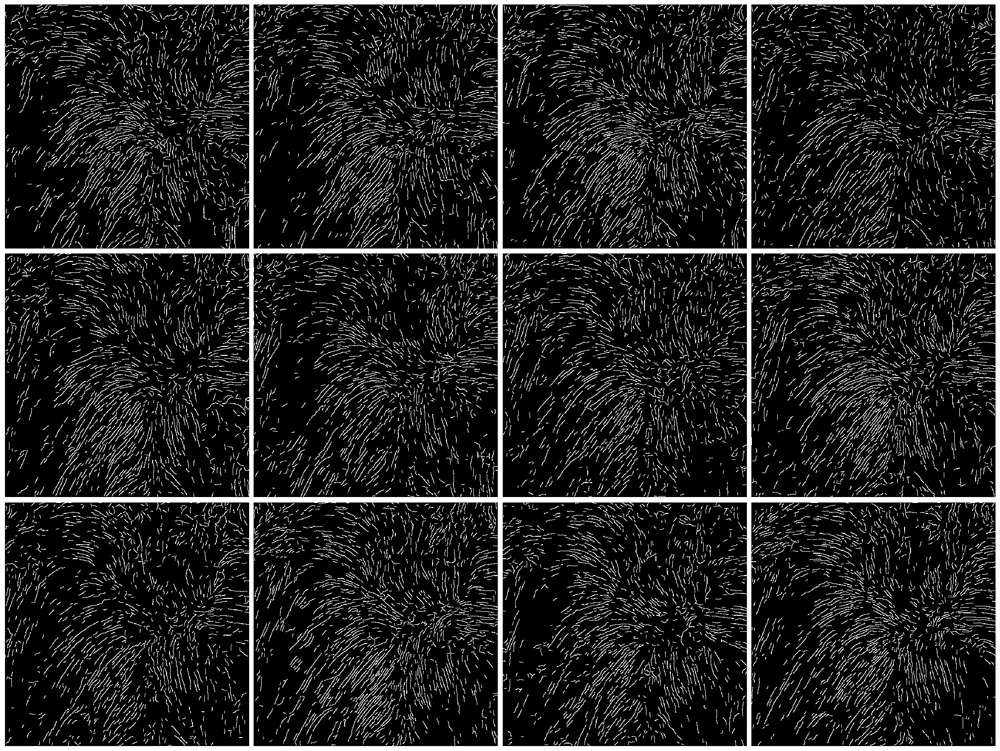

In [61]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15), layout="constrained")
for ii, ax_ in enumerate(axes.flatten()):
    ax_.imshow(
        fibril_mask_small_display[ii],
        origin="lower",
        interpolation="nearest",
        cmap="gray",
        vmin=0, vmax=1
    )
    ax_.set_axis_off()
    ax_.spines["top"].set_visible(False)
    ax_.spines["right"].set_visible(False)
    ax_.spines["bottom"].set_visible(False)
    ax_.spines["left"].set_visible(False)

fig.savefig("../../figs/test_figs/fibril_traces_ensamble.png", dpi=240)

In [62]:
np.save("../../sav/fibril_tracing/fibril_mask_ensemble.npy", fibril_mask)
np.save("../../sav/fibril_tracing/fibril_mask_small_display_ensemble.npy", fibril_mask_small_display)
np.save("../../sav/fibril_tracing/fibril_merge_ensemble.npy", fibril_merge)
np.save("../../sav/fibril_tracing/fibril_skel_raw_ensemble.npy", fibril_skel_raw)